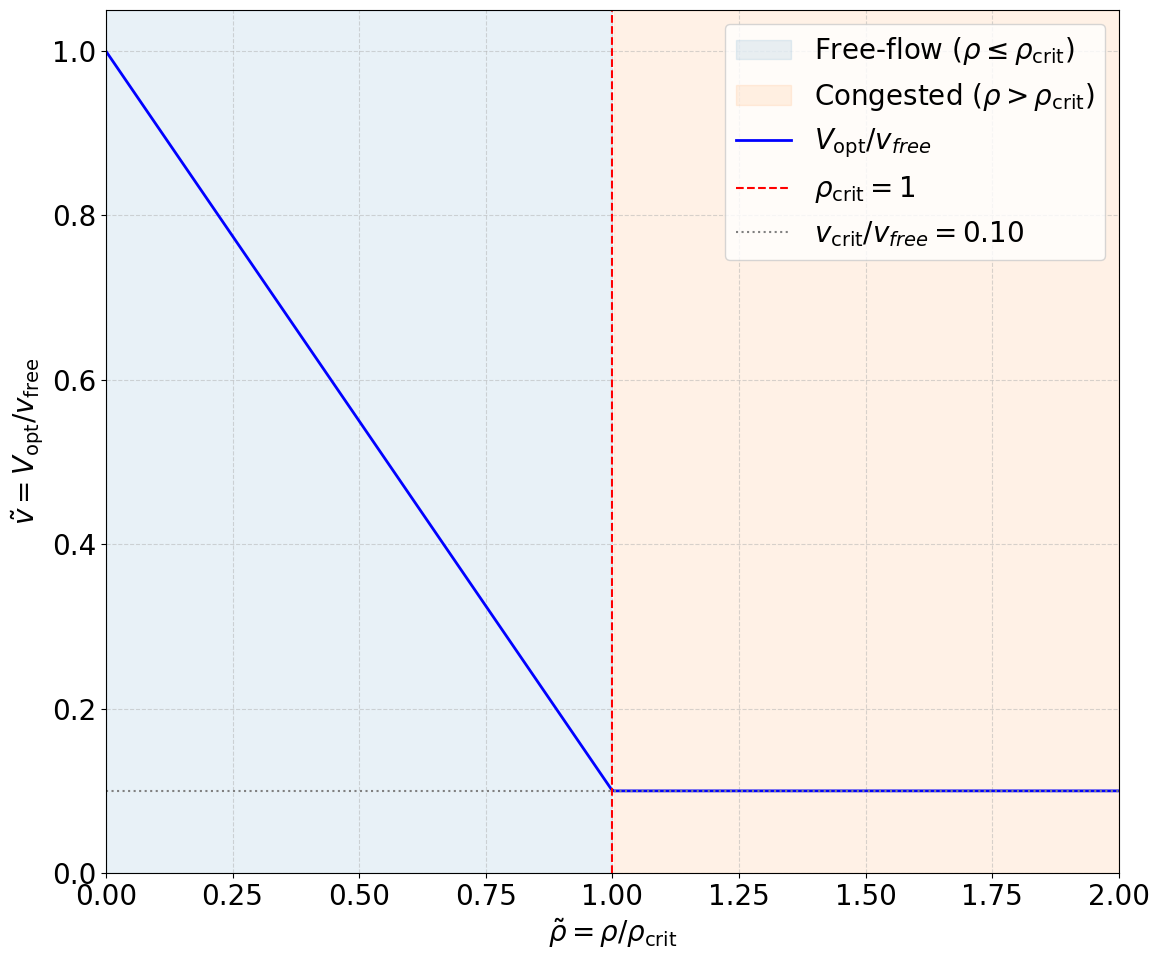

In [23]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.size'] = 20

def plot_optimal_velocity_smooth(density_crit, speed_crit, v_max):
    rho = np.linspace(0, 2, 400)
    vcrit_norm = speed_crit / v_max

    V_norm = np.where(
        rho <= 1,
        vcrit_norm + (1 - rho) * (1 - vcrit_norm),
        vcrit_norm
    )

    fig, ax = plt.subplots(figsize=(12, 10))

    ax.fill_between(rho, 0, 1.05,
                    where=(rho <= 1),
                    color='C0', alpha=0.1,
                    label=r'Free-flow ($\rho \leq \rho_{\rm crit}$)')

    ax.fill_between(rho, 0, 1.05,
                    where=(rho > 1),
                    color='C1', alpha=0.1,
                    label=r'Congested ($\rho > \rho_{\rm crit}$)')

    ax.plot(rho, V_norm, color='blue', lw=2,
            label=r'$V_{\rm opt}/v_{free}$')

    # Mark the critical density and speed
    ax.axvline(1.0, color='red', linestyle='--',
               label=r'$\rho_{\rm crit}=1$')
    ax.axhline(vcrit_norm, color='grey', linestyle=':',
               label=rf'$v_{{\rm crit}}/v_{{free}}={vcrit_norm:.2f}$')

    # Labels and limits
    ax.set_xlabel(r'$\tilde{\rho} = \rho/\rho_{\rm crit}$')
    ax.set_ylabel(r'$\tilde{v} = V_{\rm opt}/v_{\text{free}}$')
    ax.set_xlim(0, 2)
    ax.set_ylim(0, 1.05)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='upper right')
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    kcrit   = 0.2    # critical density (unused in normalization)
    vcrit   = 5.0    # critical speed
    vmax    = 50.0   # free‐flow speed

    plot_optimal_velocity_smooth(kcrit, vcrit, vmax)
